# Chapter 6 - Estimating Selection Models

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#6.2.2-Simulation-of-Censored-Data" data-toc-modified-id="6.2.2-Simulation-of-Censored-Data-1">6.2.2 Simulation of Censored Data</a></span></li><li><span><a href="#6.2.3-Latent-Value-Model" data-toc-modified-id="6.2.3-Latent-Value-Model-2">6.2.3 Latent Value Model</a></span></li><li><span><a href="#6.2.5-Tobit-Estimator-in-Python" data-toc-modified-id="6.2.5-Tobit-Estimator-in-Python-3">6.2.5 Tobit Estimator in Python</a></span></li><li><span><a href="#6.3.1-National-Longitudinal-Survey-of-Youth-1997" data-toc-modified-id="6.3.1-National-Longitudinal-Survey-of-Youth-1997-4">6.3.1 National Longitudinal Survey of Youth 1997</a></span></li><li><span><a href="#6.3.2-Tobit-Estimates" data-toc-modified-id="6.3.2-Tobit-Estimates-5">6.3.2 Tobit Estimates</a></span></li><li><span><a href="#6.4.2-Simulation-of-a-Selection-Model" data-toc-modified-id="6.4.2-Simulation-of-a-Selection-Model-6">6.4.2 Simulation of a Selection Model</a></span></li><li><span><a href="#6.4.5-Heckman-Estimator-in-Python" data-toc-modified-id="6.4.5-Heckman-Estimator-in-Python-7">6.4.5 Heckman Estimator in Python</a></span></li><li><span><a href="#6.5.1-NLSY97-Data" data-toc-modified-id="6.5.1-NLSY97-Data-8">6.5.1 NLSY97 Data</a></span></li><li><span><a href="#6.5.2-Choosing-To-Work" data-toc-modified-id="6.5.2-Choosing-To-Work-9">6.5.2 Choosing To Work</a></span></li><li><span><a href="#6.5.3-Heckman-Estimates-of-Gender-Gap" data-toc-modified-id="6.5.3-Heckman-Estimates-of-Gender-Gap-10">6.5.3 Heckman Estimates of Gender Gap</a></span></li><li><span><a href="#6.6.1-NLSM-Data" data-toc-modified-id="6.6.1-NLSM-Data-11">6.6.1 NLSM Data</a></span></li><li><span><a href="#6.6.2-College-vs.-No-College" data-toc-modified-id="6.6.2-College-vs.-No-College-12">6.6.2 College vs. No College</a></span></li><li><span><a href="#6.6.3-Choosing-College" data-toc-modified-id="6.6.3-Choosing-College-13">6.6.3 Choosing College</a></span></li><li><span><a href="#6.6.4-Heckman-Estimates-of-Returns-to-Schooling" data-toc-modified-id="6.6.4-Heckman-Estimates-of-Returns-to-Schooling-14">6.6.4 Heckman Estimates of Returns to Schooling</a></span></li><li><span><a href="#6.6.5-Effect-of-College" data-toc-modified-id="6.6.5-Effect-of-College-15">6.6.5 Effect of College</a></span></li></ul></div>

## 6.2.2 Simulation of Censored Data

In [1]:
# as in the previous chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

# main parameters of interest
N = 500
a = 2
b = -3

# the observed characteristic, x, is drawn from a uniform distribution
x = np.random.rand(N)

# the unobserved characteristic, u, is drawn from a standard normal distribution
u = np.random.normal(size = N)

# the latent outcome
ystar = a + b*x + u

# we observe ystar when it is positive, and 0 if not: y is censored at 0
# np.where() does the job of ifelse() in R
y = np.where(ystar > 0, ystar, 0)

In [4]:
# using statsmodels and pandas, as in chapters 2 and 3
import statsmodels.formula.api as sm
import pandas as pd

# pack the variables in a dataframe
data = pd.DataFrame({'y': y, 'x': x})

lm1 = sm.ols(formula="y ~ x", data=data).fit()

# the true slope is -3
# the OLS estimate is much flatter
print(lm1.params['x'])

-2.019103615265804


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

# the function of chapter 1 to plot a line from slope and intercept
# we add the style of the line (solid or dashed)
def abline(slope, intercept, linestyle='-'):
    """Plot a linear function from slope and intercept"""
    axes = plt.gca()
    x_vals = np.array(axes.get_xlim())
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, color='k', linestyle=linestyle)

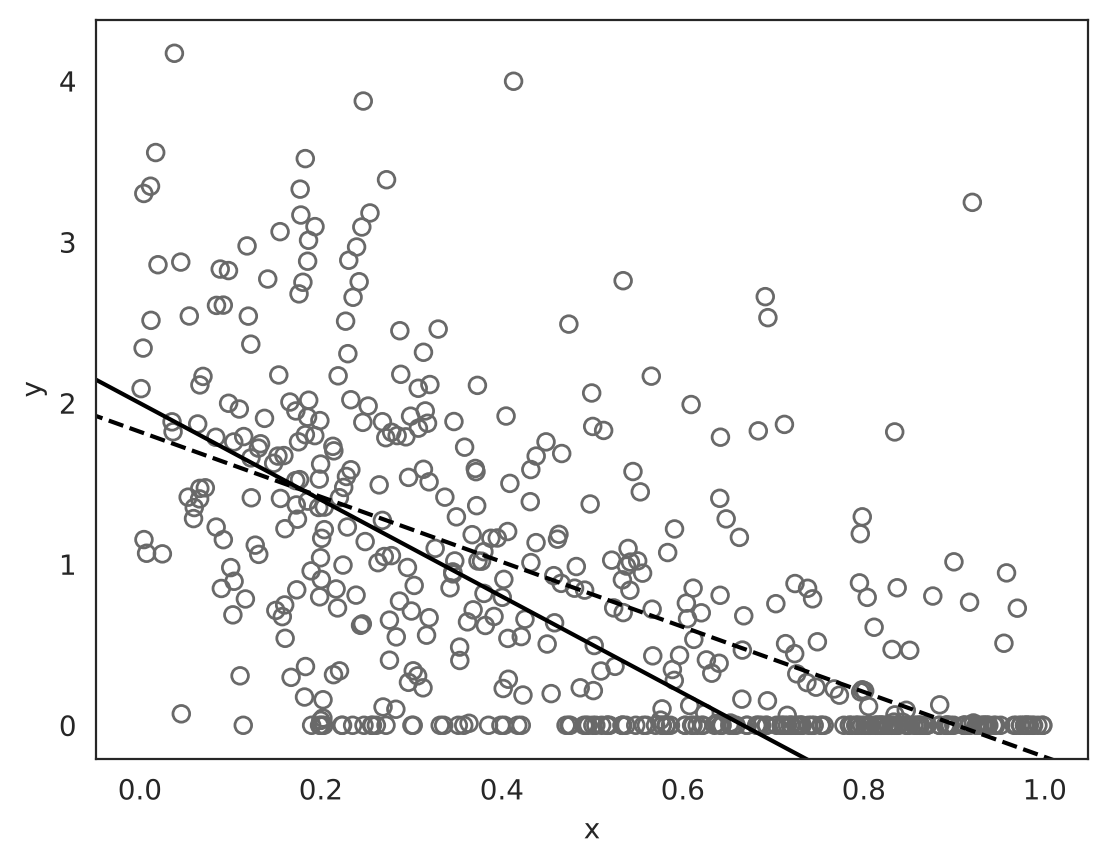

In [6]:
# plotting the dots
plt.scatter(x, y, facecolors='none', color='dimgray')

# we keep the limits of the two axes, to put them back after the lines are drawn
x_limits = plt.xlim()
y_limits = plt.ylim()

# solid line: the true relationship between ystar and x
abline(slope=b, intercept=a)

# dashed line: the relationship between y and x estimated by OLS
abline(slope=lm1.params['x'], intercept=lm1.params['Intercept'], linestyle='--')

plt.xlim(x_limits)
plt.ylim(y_limits)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [7]:
# we limit the data to the values of x below 0.6,
# where y is mostly not censored
data_small = data[data['x'] < 0.6]
print(sm.ols(formula="y ~ x", data=data_small).fit().params['x'])

-2.6862783422822036


In [8]:
# number of observations left
print(len(data_small))

309


In [9]:
# probit: is y positive or not
# statsmodels wants a 0/1 variable on the left side of the formula,
# so we create it first
data['y_positive'] = np.where(data['y'] > 0, 1, 0)

# disp=0 hides the message of the optimizer
sm.probit(formula="y_positive ~ x", data=data).fit(disp=0).params

Intercept    2.088642
x           -3.208885
dtype: float64

## 6.2.3 Latent Value Model

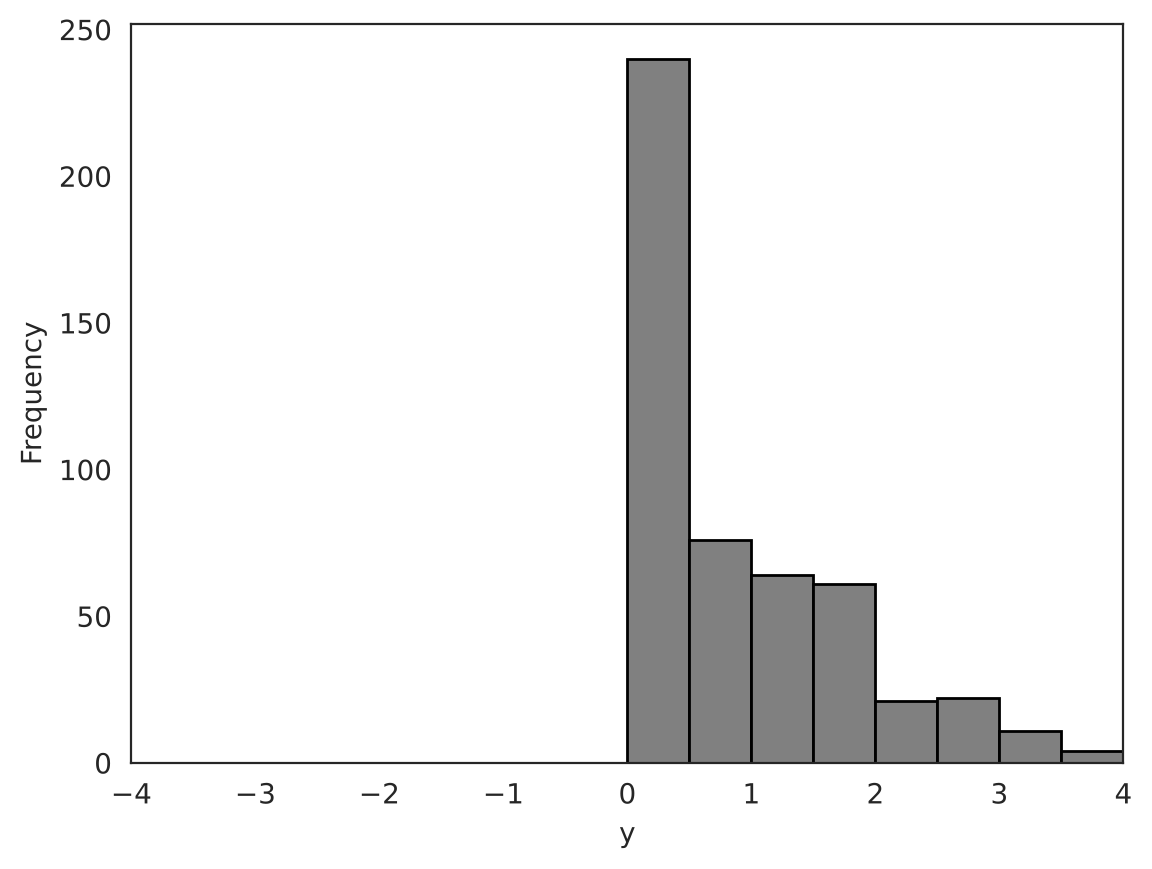

In [10]:
# histogram of the observed values of y
# the x axis starts at -4 to show the part of ystar we do not observe
plt.hist(y, bins=np.arange(0, np.max(y) + 0.5, 0.5), color='grey', edgecolor='k')
plt.xlim(-4, 4)
plt.xlabel('y')
plt.ylabel('Frequency')
plt.show()

## 6.2.5 Tobit Estimator in Python

In [11]:
from scipy.optimize import minimize
from scipy import stats

def f_tobit(para, y, X):
    """
    Tobit log-likelihood, with a minus sign
    * para: the log of sigma first, then the betas
    * y: the outcome, with a 0 when it is censored
    * X: the explanatory variables, without the column of 1's
    """
    X = np.c_[np.ones(len(y)), X]  # adds a column of 1's to the matrix
    sig = np.exp(para[0])  # use exp() to keep value positive.
    beta = para[1:]  # python starts counting at 0, so the betas start at position 1
    is0 = y == 0
    # indicator function for y = 0.
    z = (y - X.dot(beta))/sig
    # stats.norm.cdf is pnorm in R and stats.norm.pdf is dnorm
    log_lik = -np.sum(is0*np.log(stats.norm.cdf(z)) +
                      (1 - is0)*(np.log(stats.norm.pdf(z)) - np.log(sig)))
    # note the negative because we are minimizing.
    return log_lik

In [12]:
# starting values: 0 for the log of sigma, then the OLS estimates
# np.concatenate() does the job of c() in R
par1 = np.concatenate(([0], lm1.params))

# optim() in R uses the Nelder-Mead method when we do not ask for another one
# in scipy the function comes first, then the starting values,
# and args gives the other arguments of f_tobit (y and X)

# R stops when the function goes down by less than 1e-8 or so (reltol)
# scipy stops earlier (1e-4 by default), sometimes before the minimum,
# so we ask for 1e-8 with xatol (for the parameters) and fatol (for the function)
a1 = minimize(f_tobit, par1, args=(y, x), method='Nelder-Mead',
              options={'xatol': 1e-8, 'fatol': 1e-8})

# sigma (true value 1)
# the estimates are in a1.x (a1$par in R)
print(np.exp(a1.x[0]))

0.9998698290293527


In [13]:
# beta (true values 2 and -3)
a1.x[1:]

array([ 2.04769182, -3.13762687])

## 6.3.1 National Longitudinal Survey of Youth 1997

In [14]:
x = pd.read_csv('../data/NLSY97_min.csv')

# some names of columns have a "!" or a "-"
# R changes these characters to "." when it reads the file (KEY!SEX is KEY.SEX in the book)
# python keeps the names of the file
x.head()

,PUBID,KEY!SEX,KEY!BDATE_M,KEY!BDATE_Y,CV_SAMPLE_TYPE,KEY!RACE_ETHNICITY,CV_HGC_EVER_EDT,YINC-1700,CVC_HOURS_WK_YR_ALL.10
0,1,2,9,1981,1,4,16,47000,2060
1,2,1,7,1982,1,2,14,52000,3103
2,3,2,9,1983,1,2,-5,-5,2056
3,4,2,2,1981,1,2,13,41000,2170
4,5,1,10,1982,1,2,12,62000,3006


In [15]:
# We define a bunch of functions to clean the data
# in an organised fashion, as in chapter 2

def create_wage(df):
    """
    wage: income of the year divided by the hours worked in the year
    * NA when hours or income are not positive
      (in this file the negative numbers are codes for no answer)
    """
    hours = df['CVC_HOURS_WK_YR_ALL.10']
    income = df['YINC-1700']
    df['wage'] = np.where((hours > 0) & (income > 0), income/hours, np.nan)
    return df

def topcode_wage(df):
    # topcode at the 90th percentile
    # this done to remove unreasonably high measures of wages.
    # pandas leaves the NAs out of the quantile, as na.rm = TRUE in R
    q90 = df['wage'].quantile(0.90)
    df['wage'] = np.where(df['wage'] < q90, df['wage'], np.nan)
    return df

def create_lwage(df):
    # log wage when the wage is above the minimum wage of $7.25, 0 if not
    # note the 0s are used as an indicator in the Tobit function.
    # (a missing wage gives a 0 here and a NA in R, these rows are removed below)
    df['lwage'] = np.where(df['wage'] > 7.25, np.log(df['wage']), 0)
    return df

def create_ed(df):
    # removed very high values of education.
    ed = df['CV_HGC_EVER_EDT']
    df['ed'] = np.where((ed > 0) & (ed < 25), ed, np.nan)
    return df

def create_exp(df):
    df['exp'] = 2010 - df['KEY!BDATE_Y'] - df['ed'] - 6
    df['exp2'] = (df['exp']**2)/100
    # division makes the reported results nicer.
    return df

def create_female_black(df):
    # we code the two dummies in 0/1s
    df['female'] = np.where(df['KEY!SEX'] == 2, 1, 0)
    df['black'] = np.where(df['KEY!RACE_ETHNICITY'] == 1, 1, 0)
    return df

def remove_missing(df, cols):
    # keep the rows with no NA in the columns of the list cols
    return df.dropna(subset=cols)

In [16]:
# and we perform the data cleaning using the .pipe operator
# on the original dataset x

x1 = (
    x
    .pipe(create_wage)
    .pipe(topcode_wage)
    .pipe(create_lwage)
    .pipe(create_ed)
    .pipe(create_exp)
    .pipe(create_female_black)
    .pipe(remove_missing, cols = ['wage', 'ed'])
)

# number of rows and columns left
x1.shape

(4282, 16)

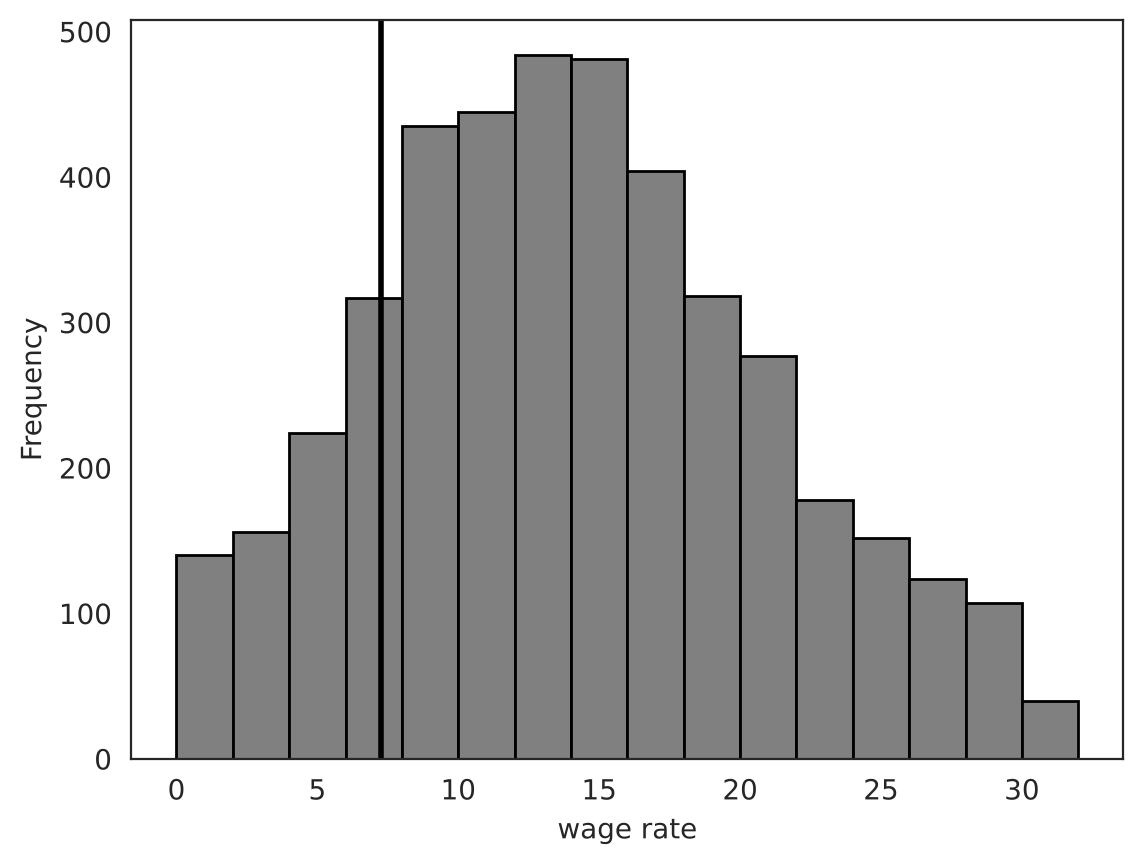

In [17]:
# histogram of the wage rates
# the vertical line is at the minimum wage of $7.25
plt.hist(x1['wage'], bins=np.arange(0, 34, 2), color='grey', edgecolor='k')
plt.axvline(7.25, color='k', linewidth=2)
plt.xlabel('wage rate')
plt.ylabel('Frequency')
plt.show()

## 6.3.2 Tobit Estimates

In [18]:
# OLS
lm1 = sm.ols(formula="lwage ~ ed + exp + exp2 + female + black", data=x1).fit()

# probit: is the wage above the minimum wage or not
# again we create the 0/1 variable first
x1['above_min'] = np.where(x1['lwage'] > 0, 1, 0)
glm1 = sm.probit(formula="above_min ~ ed + exp + exp2 + female + black", data=x1).fit(disp=0)

In [19]:
# Tobit, starting from the probit estimates
par1 = np.concatenate(([0], glm1.params))

# we use numpy arrays for y and X
y = np.array(x1['lwage'])
X = np.array(x1[['ed', 'exp', 'exp2', 'female', 'black']])

# maxiter is the maximum number of iterations (maxit in R)
a1 = minimize(f_tobit, par1, args=(y, X), method='Nelder-Mead',
              options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 10000})

In [20]:
# stacking all the results in a single dataframe
# the values for sigma are arbitrarily set to 1 for the OLS and the probit
res_tab = pd.DataFrame()
res_tab['OLS Est'] = np.append(lm1.params, 1)
res_tab['Probit Est'] = np.append(glm1.params, 1)
res_tab['Tobit Est'] = np.append(a1.x[1:], np.exp(a1.x[0]))

# name the rows of the result table
res_tab.index = ['intercept', 'ed', 'exp', 'exp sq', 'female', 'black', 'sigma']
res_tab

,OLS Est,Probit Est,Tobit Est
intercept,-0.128522,-1.514901,-0.600022
ed,0.135913,0.144853,0.157334
exp,0.117362,0.122375,0.140692
exp sq,-0.403942,-0.419840,-0.502982
female,-0.168130,-0.195637,-0.198450
black,-0.283638,-0.313497,-0.337153
sigma,1.000000,1.000000,1.222116


The Tobit estimates of exp and exp sq are not the ones of the book, because Nelder-Mead in R stops a bit before the maximum (the log-likelihood is -6703.2 at the values of the book and -6702.6 here).

## 6.4.2 Simulation of a Selection Model

In [21]:
np.random.seed(123456789)

N = 100
a = 6
b = -3
c = 4
d = -5
x = np.random.rand(N)
z = np.random.rand(N)
mu = np.array([0, 0])
sig = np.array([[1, 0.5], [0.5, 1]])

# creates a matrix with two correlated random variables.
# np.random.multivariate_normal is rmvnorm in R
u = np.random.multivariate_normal(mu, sig, N)

# z and the first column of u decide if y is observed or not
# x and the second column of u give the value of y
# python starts counting at 0, so u[:,0] is the first column
y = np.where(c + d*z + u[:,0] > 0, a + b*x + u[:,1], 0)

We now perform the regressions:

In [22]:
data = pd.DataFrame({'y1': y, 'x1': x, 'z': z})

# OLS on all the data
lm1 = sm.ols(formula="y1 ~ x1", data=data).fit()

# OLS on the data with small values of z, where y is mostly observed
lm2 = sm.ols(formula="y1 ~ x1", data=data[data['z'] < 0.6]).fit()

# probit: is y observed or not
data['y1_positive'] = np.where(data['y1'] > 0, 1, 0)
glm1 = sm.probit(formula="y1_positive ~ z", data=data).fit(disp=0)

In [23]:
from statsmodels.iolib.summary2 import summary_col

# (1) and (2) are the OLS models, (3) is the probit
# the true values are 6 and -3 for the OLS, 4 and -5 for the probit
print(summary_col([lm1,lm2,glm1],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs))}
            ))


                 (1)       (2)       (3)   
-------------------------------------------
Intercept      4.348*** 6.097***  3.510*** 
               (0.413)  (0.338)   (0.684)  
x1             -1.007   -3.126***          
               (0.718)  (0.571)            
z                                 -4.395***
                                  (0.994)  
R-squared      0.020    0.315              
R-squared Adj. 0.010    0.305              
N              100      67        100      
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 6.4.5 Heckman Estimator in Python

In [24]:
def f_heckman(par, y, X_in, Z_in=None):
    """
    Heckman log-likelihood, with a minus sign
    * par: rho first (before the sigmoid function), then the betas, then the gammas
    * y: the outcome, with a 0 when it is not observed
    * X_in: the variables which give the value of y
    * Z_in: the variables which decide if y is observed or not
    """
    # defaults to Z_in = X_in
    if Z_in is None:
        Z_in = X_in
    X = np.c_[np.ones(len(y)), X_in]
    Z = np.c_[np.ones(len(y)), Z_in]
    is0 = y == 0  # indicator function
    rho = np.exp(par[0])/(1 + np.exp(par[0]))
    # this is the sigmoid function
    # in actual fact rho is between -1 and 1, here it stays between 0 and 1
    K = X.shape[1]  # number of columns of X
    beta = par[1:(1 + K)]
    gamma = par[(1 + K):]
    Xb = X.dot(beta)
    Zg = Z.dot(gamma)
    Zg_adj = (Zg + rho*(y - Xb))/((1 - rho**2)**(.5))
    log_lik = (is0*np.log(stats.norm.cdf(-Zg)) +
               (1 - is0)*(np.log(stats.norm.cdf(Zg_adj)) +
                          np.log(stats.norm.pdf(y - Xb))))
    return -np.sum(log_lik)

In [25]:
# starting values: 0 for rho (so rho starts at 0.5),
# the OLS estimates for beta and the probit estimates for gamma
par1 = np.concatenate(([0], lm1.params, glm1.params))
a2 = minimize(f_heckman, par1, args=(y, x, z), method='Nelder-Mead',
              options={'xatol': 1e-8, 'fatol': 1e-8})

# rho (true value 0.5)
print(np.exp(a2.x[0])/(1 + np.exp(a2.x[0])))

0.34988485884809234


In [26]:
# beta (true values 6 and -3)
a2.x[1:3]

array([ 6.35024543, -3.34929687])

In [27]:
# gamma (true values 4 and -5)
a2.x[3:5]

array([ 3.51051373, -4.37638208])

## 6.5.1 NLSY97 Data

In [28]:
# the first column of the file has no name, it holds the row names of R
# we use it as the index of the dataframe
x = pd.read_csv('../data/NLSY97_gender_book.csv', index_col=0)
x.head()

,PUBID_1997,KEY_SEX_1997,KEY_BDATE_M_1997,KEY_BDATE_Y_1997,CV_SAMPLE_TYPE_1997,KEY_RACE_ETHNICITY_1997,CV_CENSUS_REGION_2007,CV_HIGHEST_DEGREE_0708_2007,CV_MARSTAT_COLLAPSED_2007,CV_MSA_2007,CV_BIO_CHILD_HH_2007,CV_URBAN-RURAL_2007,YINC-1700_2007,CVC_HOURS_WK_YR_ALL.07_XRND
1,1,2,9,1981,1,4,1.0,4.0,0.0,3.0,NaN,1.0,112215.0,1875.0
2,2,1,7,1982,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000.0
3,3,2,9,1983,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2,2,1981,1,2,1.0,2.0,0.0,2.0,1.0,1.0,32000.0,1785.0
5,5,1,10,1982,1,2,1.0,2.0,0.0,3.0,NaN,1.0,25000.0,2240.0


In the NLSY97 codes for the marital status 1 is married and 2 is separated, but the book takes 2 for `married`, and we do the same to get its numbers.

In [29]:
def create_lftwage(df):
    """
    We create new variables:
    * wage: income of 2007 divided by the hours worked in 2007
    * fulltime: more than 1750 hours in the year
    * lftwage: log wage of the full-time workers, 0 for the others
    """
    hours = df['CVC_HOURS_WK_YR_ALL.07_XRND']
    income = df['YINC-1700_2007']
    df['wage'] = np.where(hours > 0, income/hours, 0)
    df['lwage'] = np.where(df['wage'] > 1, np.log(df['wage']), 0)
    df['fulltime'] = hours > 1750
    df['lftwage'] = np.where((df['lwage'] > 0) & df['fulltime'], df['lwage'], 0)
    # R and python do not treat the missing values in the same way here
    # in R, lftwage is NA when the hours are missing,
    # and when a full-time worker has no income reported
    # in python a comparison with a NA is False, so these rows get a 0
    # we put the NAs back by hand to keep the sample of the book
    is_na = hours.isna() | (df['fulltime'] & income.isna())
    df['lftwage'] = np.where(is_na, np.nan, df['lftwage'])
    return df

def create_age(df):
    df['age'] = 2007 - df['KEY_BDATE_Y_1997']
    df['age2'] = df['age']**2
    return df

def create_dummies(df):
    # we code all the dummies in 0/1s
    df['female'] = np.where(df['KEY_SEX_1997'] == 2, 1, 0)
    df['black'] = np.where(df['KEY_RACE_ETHNICITY_1997'] == 1, 1, 0)
    df['college'] = np.where(df['CV_HIGHEST_DEGREE_0708_2007'] >= 3, 1, 0)
    df['south'] = np.where(df['CV_CENSUS_REGION_2007'] == 3, 1, 0)
    df['urban'] = np.where(df['CV_URBAN-RURAL_2007'] == 1, 1, 0)
    df['msa'] = np.where((df['CV_MSA_2007'] > 1) & (df['CV_MSA_2007'] < 5), 1, 0)
    df['married'] = np.where(df['CV_MARSTAT_COLLAPSED_2007'] == 2, 1, 0)
    df['children'] = np.where(df['CV_BIO_CHILD_HH_2007'] > 0, 1, 0)
    return df

In [30]:
# in R a dummy made from a NA is a NA, in python it is a 0
# so we remove the rows with a missing value first (remove_missing is defined in 6.3.1)
# and we create the dummies after
cols = ['lftwage', 'CV_HIGHEST_DEGREE_0708_2007', 'CV_CENSUS_REGION_2007',
        'CV_URBAN-RURAL_2007', 'CV_MSA_2007', 'CV_MARSTAT_COLLAPSED_2007',
        'CV_BIO_CHILD_HH_2007']

x1 = (
    x
    .pipe(create_lftwage)
    .pipe(remove_missing, cols = cols)
    .pipe(create_age)
    .pipe(create_dummies)
)

# split by gender
x1_f = x1[x1['female'] == 1]
x1_m = x1[x1['female'] == 0]

# number of women and number of men
print(len(x1_f), len(x1_m))

1555 1076


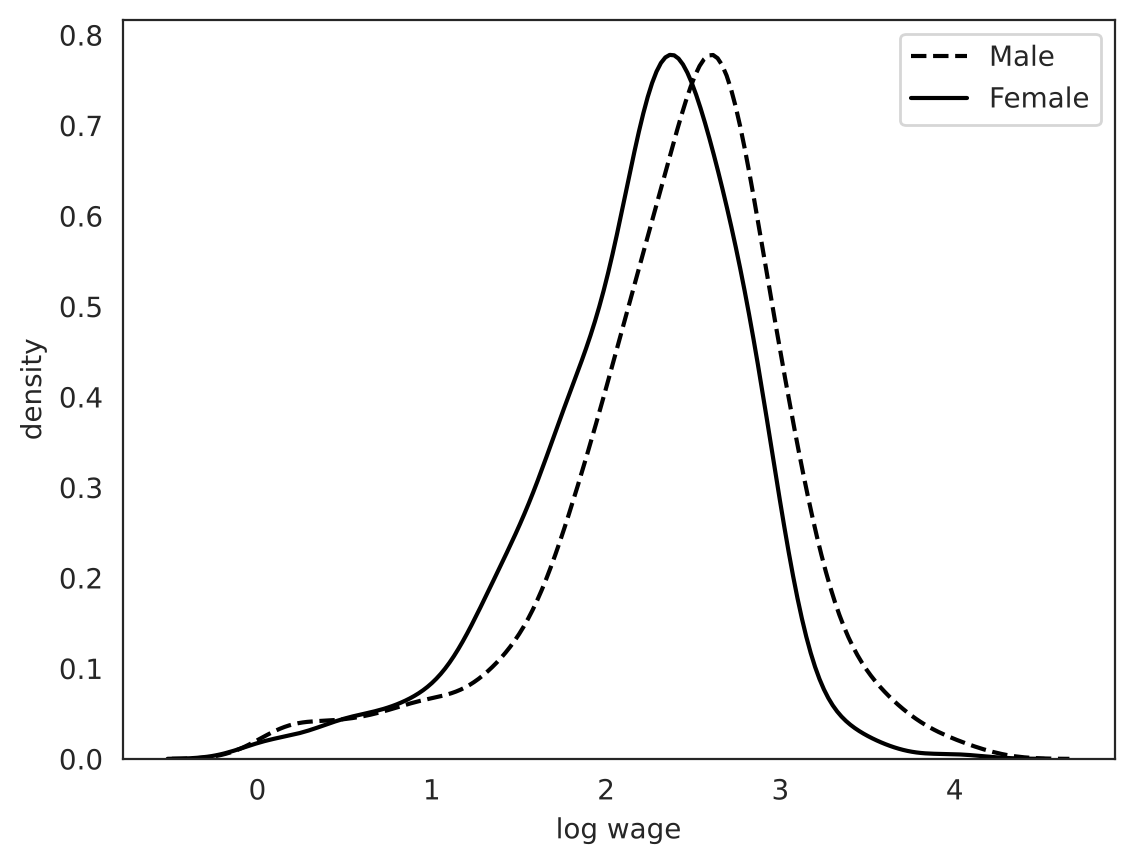

In [31]:
# density of the log wages of the full-time workers, by gender
# sns.kdeplot does the job of density() in R
sns.kdeplot(x1_m[x1_m['lftwage'] > 0]['lftwage'], color='k', linestyle='--', label='Male')
sns.kdeplot(x1_f[x1_f['lftwage'] > 0]['lftwage'], color='k', linestyle='-', label='Female')
plt.xlabel('log wage')
plt.ylabel('density')
plt.legend()
plt.show()

In [32]:
# (1) men, (2) women, (3) both with a dummy for female
lm1 = sm.ols(formula="lftwage ~ age + age2 + black + college + south + msa", data=x1_m).fit()
lm2 = sm.ols(formula="lftwage ~ age + age2 + black + college + south + msa", data=x1_f).fit()
lm3 = sm.ols(formula="lftwage ~ female + age + age2 + black + college + south + msa", data=x1).fit()

print(summary_col([lm1,lm2,lm3],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                  (1)      (2)       (3)   
-------------------------------------------
Intercept      -12.470   -5.341   -3.297   
               (14.382)  (10.084) (8.412)  
age            0.990     0.430    0.292    
               (1.148)   (0.807)  (0.672)  
age2           -0.017    -0.008   -0.004   
               (0.023)   (0.016)  (0.013)  
black          -0.660*** 0.020    -0.255***
               (0.083)   (0.057)  (0.048)  
college        0.547***  0.620*** 0.596*** 
               (0.133)   (0.082)  (0.072)  
south          0.053     -0.025   -0.012   
               (0.080)   (0.055)  (0.047)  
msa            0.030     0.038    0.048    
               (0.143)   (0.120)  (0.093)  
female                            -0.660***
                                  (0.045)  
R-squared      0.097     0.042    0.115    
R-squared Adj. 0.092     0.038    0.113    
N              1076      1555     2631     
R2             0.097     0.042    0.115    
Standard errors in parentheses.

## 6.5.2 Choosing To Work

The book calls these regressions probits, but its R code calls `glm` with no `family`, which gives a linear regression, and we do the same to get the numbers of the book.

In [33]:
# 1 if the woman works full-time, 0 if not
x1_f['work'] = np.where(x1_f['lftwage'] > 0, 1, 0)

glm1 = sm.ols(formula="work ~ college", data=x1_f).fit()
glm2 = sm.ols(formula="work ~ college + south", data=x1_f).fit()
glm3 = sm.ols(formula="work ~ college + south + married + children", data=x1_f).fit()

print(summary_col([glm1,glm2,glm3],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                 (1)      (2)      (3)   
-----------------------------------------
Intercept      0.284*** 0.278*** 0.157** 
               (0.012)  (0.016)  (0.062) 
college        0.219*** 0.218*** 0.215***
               (0.036)  (0.036)  (0.036) 
south                   0.014    0.015   
                        (0.023)  (0.023) 
married                          -0.037  
                                 (0.089) 
children                         0.126** 
                                 (0.062) 
R-squared      0.024    0.024    0.027   
R-squared Adj. 0.023    0.023    0.024   
N              1555     1555     1555    
R2             0.024    0.024    0.027   
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 6.5.3 Heckman Estimates of Gender Gap

In [34]:
# the outcome variable is normalized: mean 0 and standard deviation 1
# np.std divides by n and R's sd divides by n-1, so we set ddof=1
x1['lftwage_norm'] = (x1['lftwage'] - np.mean(x1['lftwage']))/np.std(x1['lftwage'], ddof=1)

# the 0s stay 0s, they are the indicator in the Heckman function
x1['lftwage_norm3'] = np.where(x1['lftwage'] == 0, 0, x1['lftwage_norm'])

# we use numpy arrays for y, X and Z
y1 = np.array(x1['lftwage_norm3'])
X1 = np.array(x1[['age', 'age2', 'black', 'college', 'south', 'msa']])
Z1 = np.array(x1[['college', 'south', 'married', 'children']])

# the rows of the women
female = np.array(x1['female'] == 1)
y1f = y1[female]
X1f = X1[female, :]
Z1f = Z1[female, :]

In [35]:
# starting values: the OLS estimates for women (lm2)
# and the estimates of the choice to work (glm3)
par1 = np.concatenate(([0], lm2.params, glm3.params))
a2 = minimize(f_heckman, par1, args=(y1f, X1f, Z1f), method='Nelder-Mead',
              options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 10000})

# rho
print(np.exp(a2.x[0])/(1 + np.exp(a2.x[0])))

0.9047770420900209


In [36]:
# the 7 betas are in positions 1 to 7 of a2.x (a2$par[2:8] in R)
beta = a2.x[1:8]

# wage offers of all the women, with the Heckman estimates
# X times beta plus a draw from a standard normal distribution
y_adj = np.c_[np.ones(len(X1f)), X1f].dot(beta) + np.random.normal(size = len(X1f))

# same thing with the observed characteristics of the men
# ~ means "not" for a True/False vector (! in R)
X1m = X1[~female, :]
y_adj_m = np.c_[np.ones(len(X1m)), X1m].dot(beta) + np.random.normal(size = len(X1m))

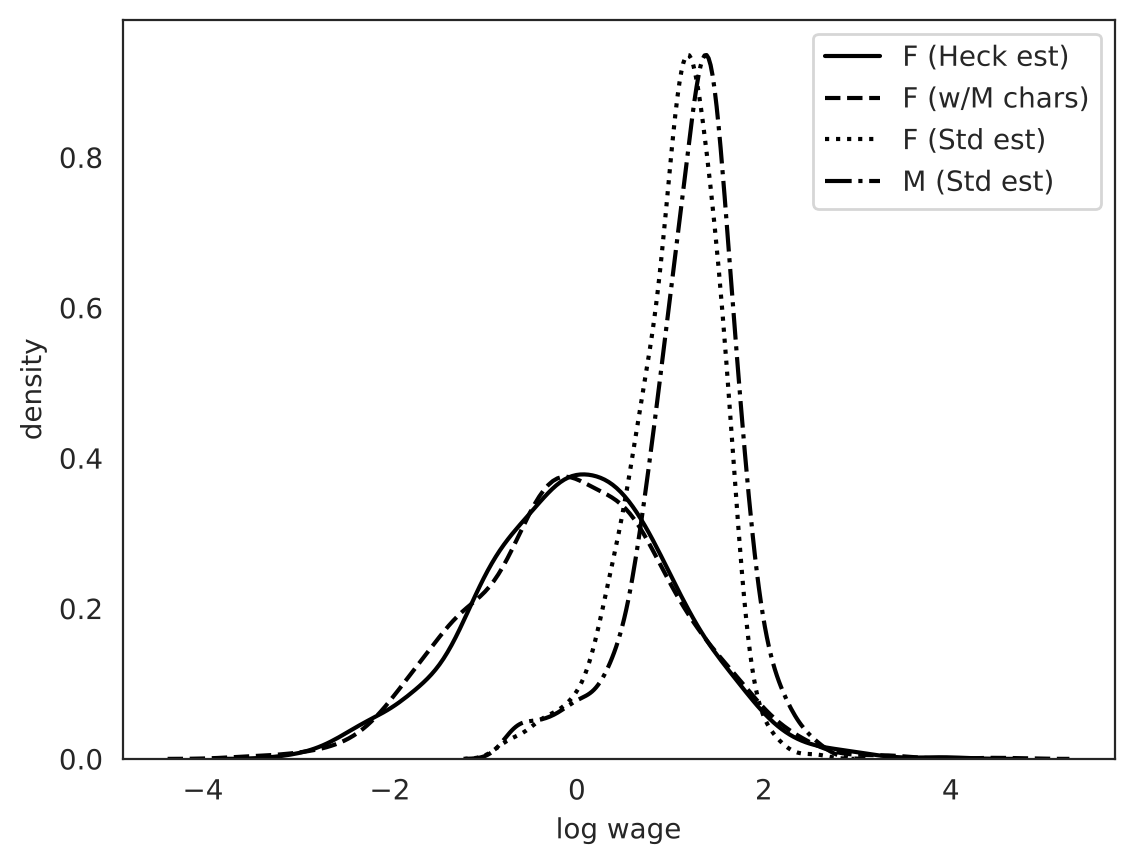

In [37]:
# observed wages of the women and of the men who work full-time
y1m = y1[~female]
y1f_obs = y1f[y1f != 0]
y1m_obs = y1m[y1m != 0]

# density of wages by gender
sns.kdeplot(y_adj, color='k', linestyle='-', label='F (Heck est)')
sns.kdeplot(y_adj_m, color='k', linestyle='--', label='F (w/M chars)')
sns.kdeplot(y1f_obs, color='k', linestyle=':', label='F (Std est)')
sns.kdeplot(y1m_obs, color='k', linestyle='-.', label='M (Std est)')
plt.xlabel('log wage')
plt.ylabel('density')
plt.legend()
plt.show()

## 6.6.1 NLSM Data

In [38]:
x = pd.read_csv('../data/nls.csv')

In [39]:
# we take the cleaning functions of chapter 2
# and we add two functions, for the normalized log wage and for the college dummy

def convert_col_to_numeric(df, col):
    # values which are not numbers (here ".") become NAs
    df[col] = pd.to_numeric(df[col], errors = 'coerce')
    return df

def normalize_lwage(df):
    # norm log wages for Heckman model
    df['lwage76_norm'] = (df['lwage76'] - np.mean(df['lwage76']))/np.std(df['lwage76'], ddof=1)
    return df

def get_working_years_after_school(df):
    """
    We create new variables:
    * exp: working years after school
    * exp2: experience squared divided by 100
    """
    df['exp'] = df['age76']-df['ed76']-6
    df['exp2'] = df['exp']**2/100
    return df

def create_college(df):
    # a person went to college with more than 12 years of education
    df['college'] = np.where(df['ed76'] > 12, 1, 0)
    return df

In [40]:
x1 = (
    x
    .pipe(convert_col_to_numeric, col = 'lwage76')
    .pipe(remove_missing, cols = ['lwage76'])
    .pipe(normalize_lwage)
    .pipe(get_working_years_after_school)
    .pipe(create_college)
)

## 6.6.2 College vs. No College

In [41]:
# (1) men who attended college, (2) men who did not
lm1c = sm.ols(formula="lwage76_norm ~ exp + exp2 + black + reg76r + smsa76r", data=x1[x1['college'] == 1]).fit()
lm1nc = sm.ols(formula="lwage76_norm ~ exp + exp2 + black + reg76r + smsa76r", data=x1[x1['college'] == 0]).fit()

print(summary_col([lm1c,lm1nc],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                  (1)       (2)   
----------------------------------
Intercept      -0.785*** -1.231***
               (0.108)   (0.209)  
exp            0.175***  0.182*** 
               (0.028)   (0.036)  
exp2           -0.603*** -0.628***
               (0.184)   (0.149)  
black          -0.372*** -0.565***
               (0.067)   (0.051)  
reg76r         -0.219*** -0.469***
               (0.050)   (0.050)  
smsa76r        0.379***  0.396*** 
               (0.056)   (0.048)  
R-squared      0.152     0.248    
R-squared Adj. 0.150     0.245    
N              1521      1489     
R2             0.152     0.248    
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 6.6.3 Choosing College

In [42]:
# Probit Estimate
glm1 = sm.probit(formula="college ~ nearc4", data=x1).fit(disp=0)
glm2 = sm.probit(formula="college ~ nearc4 + momdad14", data=x1).fit(disp=0)
glm3 = sm.probit(formula="college ~ nearc4 + momdad14 + black + smsa66r", data=x1).fit(disp=0)
glm4 = sm.probit(formula="college ~ nearc4 + momdad14 + black + smsa66r + reg662 + reg663 + reg664 + reg665 + reg666 + reg667 + reg668 + reg669", data=x1).fit(disp=0)

# .llf is the log-likelihood of the model
# some standard errors differ from the book in the third decimal:
# R's glm and statsmodels do not compute them with the same formula
print(summary_col([glm1,glm2,glm3,glm4],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)','(4)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'Log.Lik.':lambda x: "{:.3f}".format(x.llf)}
            ))


             (1)       (2)       (3)       (4)   
-------------------------------------------------
Intercept -0.196*** -0.640*** -0.442*** -0.745***
          (0.041)   (0.063)   (0.072)   (0.129)  
nearc4    0.307***  0.316***  0.223***  0.237*** 
          (0.049)   (0.050)   (0.056)   (0.058)  
momdad14            0.552***  0.411***  0.420*** 
                    (0.058)   (0.060)   (0.061)  
black                         -0.502*** -0.466***
                              (0.059)   (0.064)  
smsa66r                       0.139**   0.130**  
                              (0.055)   (0.057)  
reg662                                  0.233*   
                                        (0.122)  
reg663                                  0.277**  
                                        (0.119)  
reg664                                  0.355**  
                                        (0.142)  
reg665                                  0.198    
                                        (0.122)  

## 6.6.4 Heckman Estimates of Returns to Schooling

In [43]:
y1 = np.array(x1['lwage76_norm'])
X1 = np.array(x1[['exp', 'exp2', 'black', 'reg76r', 'smsa76r']])
Z1 = np.array(x1[['nearc4', 'momdad14', 'black', 'smsa66r',
                  'reg662', 'reg663', 'reg664', 'reg665',
                  'reg666', 'reg667', 'reg668', 'reg669']])

# the rows of the men who attended college
college = np.array(x1['college'] == 1)

In [44]:
# College
y1c = y1[college]
X1c = X1[college, :]
Z1c = Z1[college, :]

par1 = np.concatenate(([0], lm1c.params, glm4.params))
a_coll = minimize(f_heckman, par1, args=(y1c, X1c, Z1c), method='Nelder-Mead',
                  options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 100000})

In [45]:
# No college
y1nc = -y1[~college]
# negative to account for correlation in income
# and no college.
X1nc = X1[~college, :]
Z1nc = Z1[~college, :]

par1 = np.concatenate(([0], lm1nc.params, -glm4.params))
a_nocoll = minimize(f_heckman, par1, args=(y1nc, X1nc, Z1nc), method='Nelder-Mead',
                    options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 100000})

In [46]:
# Predicted wages
mu1 = np.array([0, 0])
rho1 = np.exp(a_coll.x[0])/(1 + np.exp(a_coll.x[0]))
sig1 = np.array([[1, rho1], [rho1, 1]])

# one draw of the two unobserved terms for each person
u1 = np.random.multivariate_normal(mu1, sig1, len(x1))

# the 6 betas are in positions 1 to 6
beta_c = a_coll.x[1:7]
beta_nc = a_nocoll.x[1:7]

# wage of each person with college and with no college
X1_ones = np.c_[np.ones(len(x1)), X1]
x1['coll_y'] = X1_ones.dot(beta_c) + u1[:,0]
x1['nocoll_y'] = -X1_ones.dot(beta_nc) + u1[:,1]

The two models are estimated on samples with no censored wage (no y equal to 0), so the part of the likelihood for y = 0 is never used: the betas come out as the OLS estimates of 6.6.2 and rho stays at its starting value of 0.5.

In [47]:
# the Heckman betas next to the OLS ones, for college and for no college
# (the no college model is estimated on minus the wage, so we change its sign)
tab_beta = pd.DataFrame()
tab_beta['Heckman college'] = beta_c
tab_beta['OLS college'] = np.array(lm1c.params)
tab_beta['Heckman no college'] = -beta_nc
tab_beta['OLS no college'] = np.array(lm1nc.params)
tab_beta.index = ['intercept', 'exp', 'exp2', 'black', 'reg76r', 'smsa76r']
tab_beta

,Heckman college,OLS college,Heckman no college,OLS no college
intercept,-0.784910,-0.784910,-1.230871,-1.230871
exp,0.174940,0.174940,0.181680,0.181680
exp2,-0.602950,-0.602950,-0.628429,-0.628429
black,-0.371602,-0.371602,-0.565302,-0.565302
reg76r,-0.219455,-0.219455,-0.469275,-0.469275
smsa76r,0.378632,0.378632,0.396474,0.396474


In [48]:
# rho of the college model
print(rho1)

0.4997640593701413


## 6.6.5 Effect of College

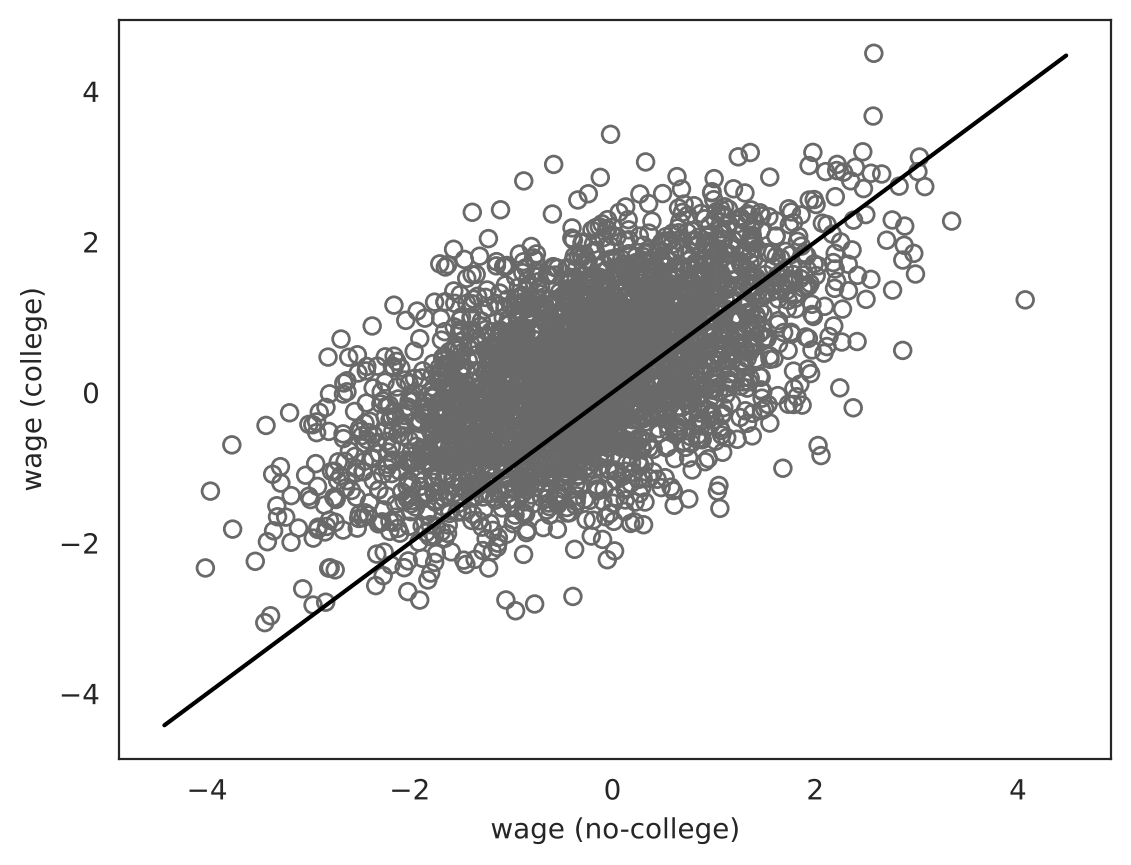

In [49]:
# predicted wage of each person with college and with no college
plt.scatter(x1['nocoll_y'], x1['coll_y'], facecolors='none', color='dimgray')

# the 45 degree line
abline(slope=1, intercept=0)

plt.xlabel('wage (no-college)')
plt.ylabel('wage (college)')
plt.show()

In [50]:
# average effect of college, divided by 4 to get the per-year effect
print(np.mean(x1['coll_y'] - x1['nocoll_y'])/4)

0.1353815035138947
